In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [4]:
# Load the cleaned dataset from Phase 1
df = pd.read_csv("CaseStudy_Jan_Samadhan_Grievances_Cleaned.csv")

# Convert date columns
df["startdate"] = pd.to_datetime(
    df["startdate"], format="%Y-%m-%d", errors="coerce"
)

df["enddate"] = pd.to_datetime(
    df["enddate"], format="%Y-%m-%d", errors="coerce"
)

print("Phase 1 dataset loaded successfully!")

display(df.head())

Phase 1 dataset loaded successfully!


,Department,Status,CitizenComplaintNarrative,ComplaintID,State,category,startdate,enddate,ResolutionDays,ComplaintMonth
0,Electricity Department,In Progress,there are frequent power interruptions in our ...,JSM100001,Telangana,Poor Service Quality,2025-05-23,NaT,NaN,2025-05
1,Electricity Department,Resolved,the electricity bill contains incorrect charges,JSM100002,Tamil Nadu,Poor Service Quality,2025-02-02,2025-02-07,5.0,2025-02
2,Electricity Department,Resolved,my electricity connection application has not ...,JSM100003,Andhra Pradesh,Poor Service Quality,2025-01-28,2025-04-11,73.0,2025-01
3,Public Works Department,In Progress,construction work on the public road has remai...,JSM100004,Delhi,Infrastructure Issues,2026-08-27,NaT,NaN,2026-08
4,Health Department,Resolved,i visited the government hospital several time...,JSM100005,Karnataka,Poor Service Quality,2025-12-15,2026-01-21,37.0,2025-12


In [16]:
# Select input and target columns
X = df["CitizenComplaintNarrative"].fillna("")
y = df["Department"]

# Remove records with empty complaint narratives or missing targets
valid_records = X.str.strip().ne("") & y.notna()

X = X[valid_records]
y = y[valid_records]

print("Total records for ML:", len(X))
print("\nDepartment distribution:")
print(y.value_counts())

Total records for ML: 900

Department distribution:
Department
Police Department             101
Health Department             100
Electricity Department         94
Water Resources Department     89
Social Welfare Department      88
Transport Department           87
Education Department           87
Public Works Department        85
Revenue Department             85
Pension Department             84
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import GroupShuffleSplit

# Split based on unique complaint narratives
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=X)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Unique training narratives:", X_train.nunique())
print("Unique testing narratives:", X_test.nunique())

Training records: 722
Testing records: 178
Unique training narratives: 40
Unique testing narratives: 10


In [19]:
# Create machine learning pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        stop_words="english"
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Department classification model trained successfully!")

Department classification model trained successfully!


In [22]:
# Prepare category target
y_category = df.loc[X.index, "category"]

# Use the same train/test indices
y_category_train = y_category.iloc[train_idx]
y_category_test = y_category.iloc[test_idx]

# Create category classification model
category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        stop_words="english"
    )),

    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train category model
category_model.fit(X_train, y_category_train)

print("Category classification model trained successfully!")

Category classification model trained successfully!


In [23]:
# Predict departments for test complaints
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Department Prediction Accuracy:",
      round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Department Prediction Accuracy: 47.19 %

Classification Report:
                            precision    recall  f1-score   support

      Education Department       0.00      0.00      0.00        11
         Health Department       0.63      1.00      0.77        27
        Pension Department       0.43      0.59      0.50        44
         Police Department       1.00      1.00      1.00        15
   Public Works Department       0.00      0.00      0.00        16
        Revenue Department       0.00      0.00      0.00        15
 Social Welfare Department       0.00      0.00      0.00        19
Water Resources Department       1.00      0.52      0.68        31

                  accuracy                           0.47       178
                 macro avg       0.38      0.39      0.37       178
              weighted avg       0.46      0.47      0.44       178



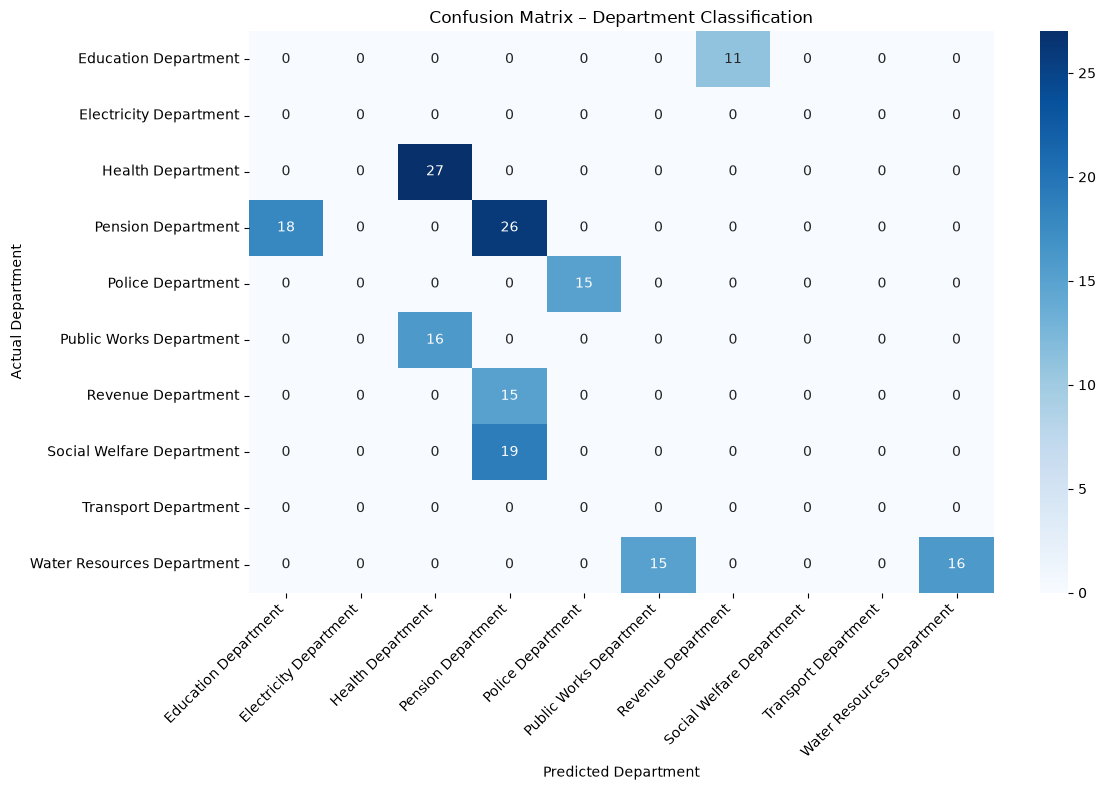

In [24]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix – Department Classification")
plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
# Predict complaint categories
category_pred = category_model.predict(X_test)

# Calculate category accuracy
category_accuracy = accuracy_score(
    y_category_test,
    category_pred
)

print("Category Prediction Accuracy:",
      round(category_accuracy * 100, 2), "%")

# Classification report
print("\nCategory Classification Report:")
print(classification_report(
    y_category_test,
    category_pred,
    zero_division=0
))

Category Prediction Accuracy: 64.04 %

Category Classification Report:
                         precision    recall  f1-score   support

  Administrative Issues       0.38      0.42      0.40        26
  Infrastructure Issues       1.00      0.66      0.79        47
Non-Receipt of Benefits       0.75      0.71      0.73        63
   Poor Service Quality       0.47      1.00      0.64        27
          Public Safety       0.00      0.00      0.00        15

               accuracy                           0.64       178
              macro avg       0.52      0.56      0.51       178
           weighted avg       0.66      0.64      0.62       178



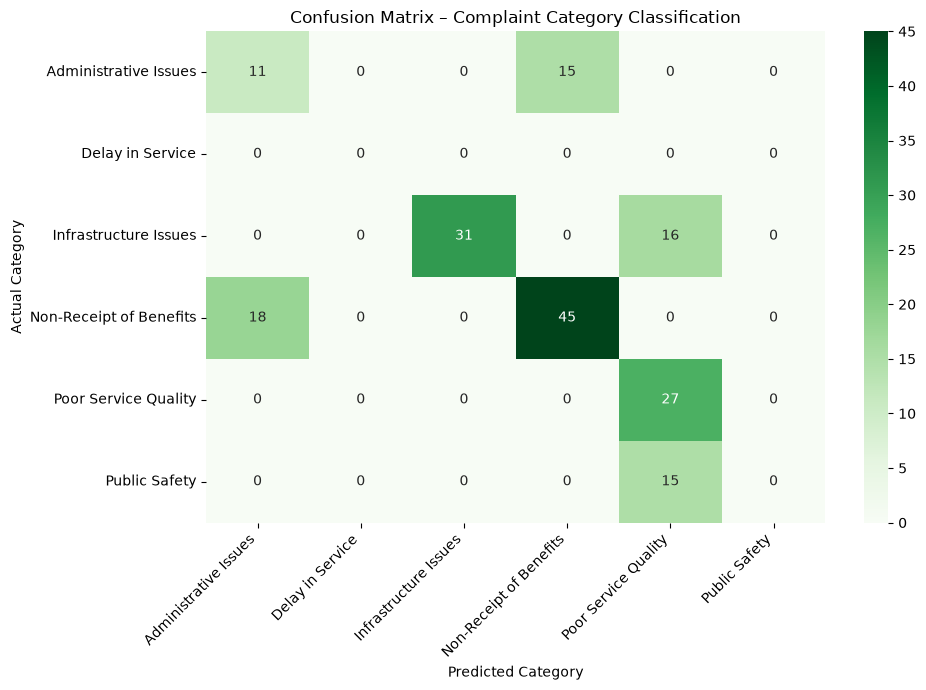

In [26]:
cm_category = confusion_matrix(
    y_category_test,
    category_pred,
    labels=category_model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_category,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=category_model.classes_,
    yticklabels=category_model.classes_
)

plt.title("Confusion Matrix – Complaint Category Classification")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
# New complaint entered by a citizen
new_complaint = [
    "My monthly pension amount has not been credited to my account."
]

# Predict department
predicted_department = model.predict(new_complaint)[0]

# Predict category
predicted_category = category_model.predict(new_complaint)[0]

print("NEW CITIZEN COMPLAINT")
print("------------------------------")
print("Complaint:", new_complaint[0])

print("\nAI-ASSISTED ROUTING RESULT")
print("------------------------------")
print("Predicted Department:", predicted_department)
print("Predicted Category:", predicted_category)

#Not accurate prediction. Need to finetune

NEW CITIZEN COMPLAINT
------------------------------
Complaint: My monthly pension amount has not been credited to my account.

AI-ASSISTED ROUTING RESULT
------------------------------
Predicted Department: Education Department
Predicted Category: Administrative Issues


In [30]:
# why a lightweight conventional ML model (like Logistic Regression) was chosen?

# Logistic Regression was selected because it is lightweight, computationally 
# efficient and works effectively with TF-IDF features for text classification. 
# The prototype uses a relatively small dataset of 900 grievance records, which 
# is insufficient to train a deep neural network or BERT model from scratch 
# effectively. 
# Conventional machine-learning models require fewer computational 
# resources, are easier to implement and provide faster training and prediction. 
# Therefore, Logistic Regression is a practical and cost-effective choice for 
# demonstrating AI-assisted grievance routing in this prototype.